# 🕵️ UPI Fraud Rings: starter notebook
**ML Gradient Wars 2026**

This notebook loads the data, looks at it, builds **single-row** features, trains a gradient-boosting model and writes a valid `submission.csv`.

It is a **baseline**. It looks at each payment on its own, so it can't see mule accounts, shared phones, money chains or repeated refunds. It scores low. Beating it is your job.

It runs in a few minutes on a laptop with 8 GB RAM. Put it in the same folder as the data files (or change `DATA` below).

## Look at the data

## Single-row features
Only what is in the row itself, plus the sender's home city from `accounts.csv`. No information about other rows.

## Validate, then train
A random split is the easy way, and it **overestimates** your score: test is a later month. A fairer check is to train on Jul–Aug and validate on September. Try both and compare.

Our approach and code


In [2]:

import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dataset paths
ZIP_PATH = r"C:\Users\Lenovo\Downloads\upi-fraud-rings-gradient-wars.zip"
DATA_DIR = r"C:\Users\Lenovo\Downloads\upi-fraud-rings"

# Extract ZIP only if the folder does not already contain the dataset
os.makedirs(DATA_DIR, exist_ok=True)

if not all(os.path.exists(os.path.join(DATA_DIR, f)) 
           for f in ["train.csv", "test.csv", "accounts.csv", "merchants.csv"]):

    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(r"C:\Users\Lenovo\Downloads")

# Base directory
BASE = DATA_DIR

# Load datasets
train = pd.read_csv(os.path.join(BASE, "train.csv"), parse_dates=["timestamp"])
test = pd.read_csv(os.path.join(BASE, "test.csv"), parse_dates=["timestamp"])
accounts = pd.read_csv(os.path.join(BASE, "accounts.csv"))
merchants = pd.read_csv(os.path.join(BASE, "merchants.csv"))

# Display dataset information
print("Train:", train.shape)
print("Test:", test.shape)
print("Accounts:", accounts.shape)
print("Merchants:", merchants.shape)

print("\nLoaded successfully!")



Train: (1564060, 22)
Test: (260582, 21)
Accounts: (420000, 6)
Merchants: (30000, 4)

Loaded successfully!


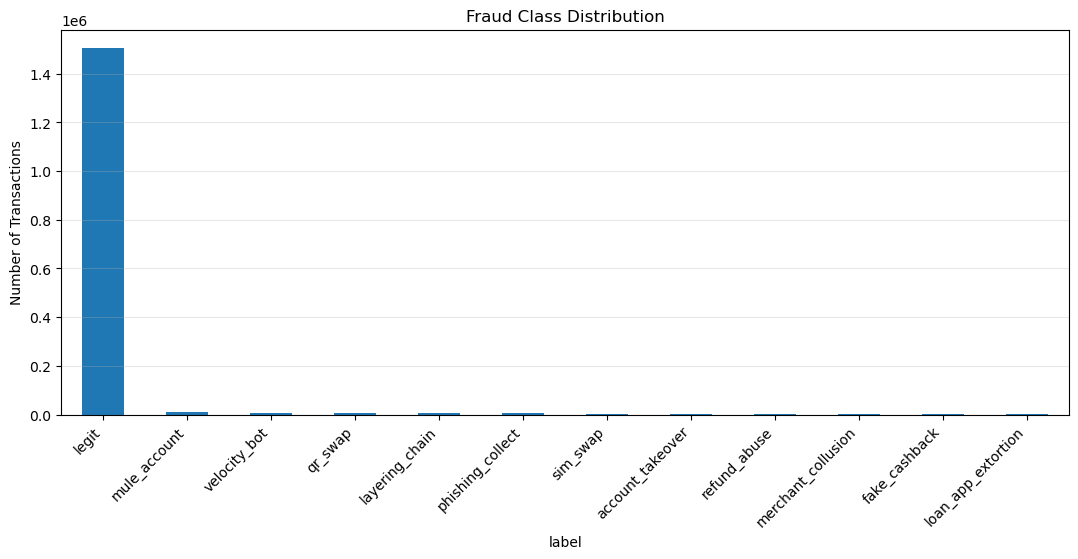

Legitimate percentage: 96.31

Class percentages:
label
legit                 96.314
mule_account           0.656
velocity_bot           0.518
qr_swap                0.464
layering_chain         0.436
phishing_collect       0.428
sim_swap               0.260
account_takeover       0.259
refund_abuse           0.211
merchant_collusion     0.163
fake_cashback          0.162
loan_app_extortion     0.127
Name: count, dtype: float64


In [3]:

class_counts = train["label"].value_counts()

plt.figure(figsize=(13, 5))
class_counts.plot(kind="bar")
plt.title("Fraud Class Distribution")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Legitimate percentage:",
      round(100 * (train.label == "legit").mean(), 2))

print("\nClass percentages:")
print((class_counts / len(train) * 100).round(3))


TRAIN MONTHLY DISTRIBUTION
month
2026-07    527065
2026-08    526852
2026-09    509996
2026-10       147
Name: count, dtype: int64

TEST MONTHLY DISTRIBUTION
month
2026-10    260536
2026-11        46
Name: count, dtype: int64


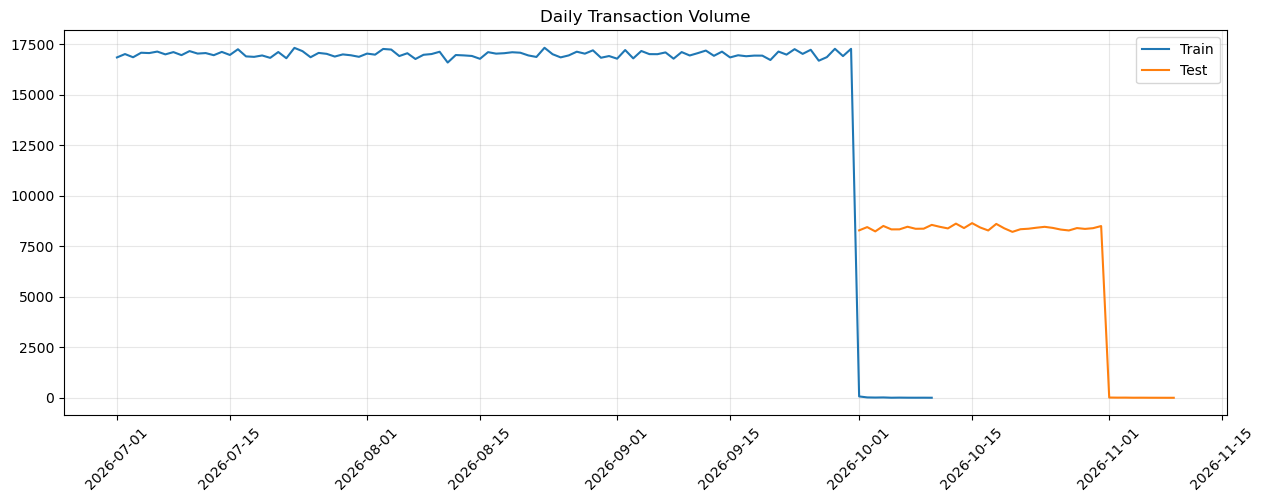

In [4]:

train["month"] = train.timestamp.dt.to_period("M").astype(str)
test["month"] = test.timestamp.dt.to_period("M").astype(str)

print("TRAIN MONTHLY DISTRIBUTION")
print(train.month.value_counts().sort_index())

print("\nTEST MONTHLY DISTRIBUTION")
print(test.month.value_counts().sort_index())

daily_train = train.groupby(
    train.timestamp.dt.date
).size()

daily_test = test.groupby(
    test.timestamp.dt.date
).size()

plt.figure(figsize=(15, 5))
plt.plot(daily_train.index, daily_train.values, label="Train")
plt.plot(daily_test.index, daily_test.values, label="Test")
plt.legend()
plt.title("Daily Transaction Volume")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()


In [5]:

numeric_cols = [
    "amount",
    "sim_age_hours",
    "device_age_days",
    "sender_account_age_days",
    "pin_retries",
    "login_to_txn_sec",
    "balance_before",
    "ip_risk_score"
]

print(
    train.groupby("label")[numeric_cols]
    .median()
    .round(2)
    .T
)


label                    account_takeover  fake_cashback  layering_chain  \
amount                             636.00         465.36         1335.61   
sim_age_hours                     5438.80        6298.90         6124.05   
device_age_days                    143.60         225.15          218.75   
sender_account_age_days            589.00         605.50          574.00   
pin_retries                          0.00           0.00            0.00   
login_to_txn_sec                    40.00          43.00           45.00   
balance_before                    4593.65        7292.17        10682.61   
ip_risk_score                        0.23           0.23            0.24   

label                      legit  loan_app_extortion  merchant_collusion  \
amount                    460.00              925.47              745.89   
sim_age_hours            6213.90             5864.00             5999.20   
device_age_days           220.50              220.00              220.30   
sender_acco

In [6]:

features = [
    "amount",
    "balance_before",
    "ip_risk_score",
    "sim_age_hours",
    "device_age_days",
    "sender_account_age_days",
    "login_to_txn_sec",
    "pin_retries"
]

drift = pd.DataFrame({
    "train_mean": train[features].mean(),
    "test_mean": test[features].mean(),
    "train_median": train[features].median(),
    "test_median": test[features].median()
})

drift["mean_change_pct"] = (
    (drift.test_mean - drift.train_mean)
    / drift.train_mean * 100
)

print(drift.round(3))


                         train_mean  test_mean  train_median  test_median  \
amount                     1245.098   1434.396       463.865      541.215   
balance_before            11278.598  11461.911      6286.180     6399.195   
ip_risk_score                 0.203      0.220         0.181        0.211   
sim_age_hours              8963.671   8916.846      6207.200     6183.200   
device_age_days             291.123    307.389       219.800      241.300   
sender_account_age_days     889.148    950.651       590.000      651.000   
login_to_txn_sec             66.895     66.895        45.000       45.000   
pin_retries                   0.121      0.120         0.000        0.000   

                         mean_change_pct  
amount                            15.203  
balance_before                     1.625  
ip_risk_score                      8.375  
sim_age_hours                     -0.522  
device_age_days                    5.587  
sender_account_age_days            6.917  
login

In [7]:

account_info = accounts.set_index("account_id")

train["sender_home_city"] = train["sender_id"].map(
    account_info["home_city"]
)

test["sender_home_city"] = test["sender_id"].map(
    account_info["home_city"]
)

train["away_from_home"] = (
    train["device_city"] != train["sender_home_city"]
).astype("int8")

test["away_from_home"] = (
    test["device_city"] != test["sender_home_city"]
).astype("int8")

print("TRAIN: away from home")
print(train.groupby("label")["away_from_home"].mean().round(3))

print("\nTRAIN: account metadata")
print(train["sender_id"].map(
    account_info["kyc_level"]
).value_counts(normalize=True).round(3))

print("\nMerchant join coverage")
print(
    test.loc[test.receiver_type == "MERCHANT", "receiver_id"]
    .isin(merchants.merchant_id).mean()
)


TRAIN: away from home
label
account_takeover      0.272
fake_cashback         0.062
layering_chain        0.068
legit                 0.068
loan_app_extortion    0.088
merchant_collusion    0.063
mule_account          0.066
phishing_collect      0.075
qr_swap               0.069
refund_abuse          0.069
sim_swap              0.153
velocity_bot          0.069
Name: away_from_home, dtype: float64

TRAIN: account metadata
sender_id
full    0.822
min     0.178
Name: proportion, dtype: float64

Merchant join coverage
1.0


In [8]:
import pandas as pd

for name, df in {
    "TRAIN": train,
    "TEST": test,
    "ACCOUNTS": accounts,
    "MERCHANTS": merchants
}.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values (%):")
    print((df.isnull().mean() * 100).round(2))

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nSample:")
    display(df.head(3))


TRAIN

Columns:
['txn_id', 'timestamp', 'sender_id', 'receiver_id', 'receiver_type', 'device_id', 'amount', 'txn_type', 'merchant_category', 'device_city', 'sim_age_hours', 'device_age_days', 'sender_account_age_days', 'new_payee', 'pin_retries', 'login_to_txn_sec', 'balance_before', 'app', 'app_version', 'ip_risk_score', 'qr_vpa_mismatch', 'label', 'month', 'sender_home_city', 'away_from_home']

Data types:
txn_id                             object
timestamp                  datetime64[ns]
sender_id                          object
receiver_id                        object
receiver_type                      object
device_id                          object
amount                            float64
txn_type                           object
merchant_category                  object
device_city                        object
sim_age_hours                     float64
device_age_days                   float64
sender_account_age_days             int64
new_payee                           int64

,txn_id,timestamp,sender_id,receiver_id,receiver_type,device_id,amount,txn_type,merchant_category,device_city,...,login_to_txn_sec,balance_before,app,app_version,ip_risk_score,qr_vpa_mismatch,label,month,sender_home_city,away_from_home
0,TX7a868970,2026-09-04 15:37:17,AC317348,MR010440,MERCHANT,DV0317348,170.50,QR,fuel,Mathura,...,79,3129.28,APP_C,4.1,0.023,0.0,legit,2026-09,Patna,1
1,TXb66b1c88,2026-08-16 16:16:20,AC228233,MR017060,MERCHANT,DV0228233,53.24,PAY,pharmacy,Ahmedabad,...,38,1746.10,APP_A,4.0,0.187,NaN,legit,2026-08,Ahmedabad,0
2,TX29a953e6,2026-07-09 05:31:01,AC291565,MR016785,MERCHANT,DV0291565,153.04,QR,ecommerce,Amritsar,...,64,6817.73,APP_E,4.8,0.284,0.0,legit,2026-07,Amritsar,0



TEST

Columns:
['txn_id', 'timestamp', 'sender_id', 'receiver_id', 'receiver_type', 'device_id', 'amount', 'txn_type', 'merchant_category', 'device_city', 'sim_age_hours', 'device_age_days', 'sender_account_age_days', 'new_payee', 'pin_retries', 'login_to_txn_sec', 'balance_before', 'app', 'app_version', 'ip_risk_score', 'qr_vpa_mismatch', 'month', 'sender_home_city', 'away_from_home']

Data types:
txn_id                             object
timestamp                  datetime64[ns]
sender_id                          object
receiver_id                        object
receiver_type                      object
device_id                          object
amount                            float64
txn_type                           object
merchant_category                  object
device_city                        object
sim_age_hours                     float64
device_age_days                   float64
sender_account_age_days             int64
new_payee                           int64
pin_retri

,txn_id,timestamp,sender_id,receiver_id,receiver_type,device_id,amount,txn_type,merchant_category,device_city,...,pin_retries,login_to_txn_sec,balance_before,app,app_version,ip_risk_score,qr_vpa_mismatch,month,sender_home_city,away_from_home
0,TX59965ca6,2026-10-31 19:08:29,AC083485,MR002226,MERCHANT,DV0083485,718.24,PAY,grocery,Agra,...,0,172,2082.99,APP_A,5.2,0.242,NaN,2026-10,Agra,0
1,TX5c06c644,2026-10-18 06:34:14,AC020563,MR004384,MERCHANT,DV0020563,767.37,PAY,fuel,Raipur,...,1,112,2753.32,APP_A,5.2,0.145,NaN,2026-10,Raipur,0
2,TX8863ee8a,2026-10-13 11:47:36,AC020104,MR019579,MERCHANT,DV0020104,365.77,QR,grocery,Dehradun,...,0,64,1272.11,APP_A,5.1,0.257,0.0,2026-10,Dehradun,0



ACCOUNTS

Columns:
['account_id', 'home_city', 'bank_code', 'kyc_level', 'opened_on', 'os']

Data types:
account_id    object
home_city     object
bank_code     object
kyc_level     object
opened_on     object
os            object
dtype: object

Missing values (%):
account_id    0.0
home_city     0.0
bank_code     0.0
kyc_level     0.0
opened_on     0.0
os            0.0
dtype: float64

Duplicate rows: 0

Sample:


,account_id,home_city,bank_code,kyc_level,opened_on,os
0,AC000000,Raipur,B28,full,2021-01-12,ios
1,AC000001,Nagpur,B26,full,2025-12-12,android
2,AC000002,Patna,B25,full,2022-08-24,android



MERCHANTS

Columns:
['merchant_id', 'category', 'city', 'onboarded_on']

Data types:
merchant_id     object
category        object
city            object
onboarded_on    object
dtype: object

Missing values (%):
merchant_id     0.0
category        0.0
city            0.0
onboarded_on    0.0
dtype: float64

Duplicate rows: 0

Sample:


,merchant_id,category,city,onboarded_on
0,MR000000,fuel,Ranchi,2025-07-08
1,MR000001,grocery,Ranchi,2025-10-07
2,MR000002,grocery,Chandigarh,2025-05-10


In [9]:
import pandas as pd

for name, df in {
    "TRAIN": train,
    "TEST": test,
    "ACCOUNTS": accounts,
    "MERCHANTS": merchants
}.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values (%):")
    print((df.isnull().mean() * 100).round(2))

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nSample:")
    display(df.head(3))


TRAIN

Columns:
['txn_id', 'timestamp', 'sender_id', 'receiver_id', 'receiver_type', 'device_id', 'amount', 'txn_type', 'merchant_category', 'device_city', 'sim_age_hours', 'device_age_days', 'sender_account_age_days', 'new_payee', 'pin_retries', 'login_to_txn_sec', 'balance_before', 'app', 'app_version', 'ip_risk_score', 'qr_vpa_mismatch', 'label', 'month', 'sender_home_city', 'away_from_home']

Data types:
txn_id                             object
timestamp                  datetime64[ns]
sender_id                          object
receiver_id                        object
receiver_type                      object
device_id                          object
amount                            float64
txn_type                           object
merchant_category                  object
device_city                        object
sim_age_hours                     float64
device_age_days                   float64
sender_account_age_days             int64
new_payee                           int64

,txn_id,timestamp,sender_id,receiver_id,receiver_type,device_id,amount,txn_type,merchant_category,device_city,...,login_to_txn_sec,balance_before,app,app_version,ip_risk_score,qr_vpa_mismatch,label,month,sender_home_city,away_from_home
0,TX7a868970,2026-09-04 15:37:17,AC317348,MR010440,MERCHANT,DV0317348,170.50,QR,fuel,Mathura,...,79,3129.28,APP_C,4.1,0.023,0.0,legit,2026-09,Patna,1
1,TXb66b1c88,2026-08-16 16:16:20,AC228233,MR017060,MERCHANT,DV0228233,53.24,PAY,pharmacy,Ahmedabad,...,38,1746.10,APP_A,4.0,0.187,NaN,legit,2026-08,Ahmedabad,0
2,TX29a953e6,2026-07-09 05:31:01,AC291565,MR016785,MERCHANT,DV0291565,153.04,QR,ecommerce,Amritsar,...,64,6817.73,APP_E,4.8,0.284,0.0,legit,2026-07,Amritsar,0



TEST

Columns:
['txn_id', 'timestamp', 'sender_id', 'receiver_id', 'receiver_type', 'device_id', 'amount', 'txn_type', 'merchant_category', 'device_city', 'sim_age_hours', 'device_age_days', 'sender_account_age_days', 'new_payee', 'pin_retries', 'login_to_txn_sec', 'balance_before', 'app', 'app_version', 'ip_risk_score', 'qr_vpa_mismatch', 'month', 'sender_home_city', 'away_from_home']

Data types:
txn_id                             object
timestamp                  datetime64[ns]
sender_id                          object
receiver_id                        object
receiver_type                      object
device_id                          object
amount                            float64
txn_type                           object
merchant_category                  object
device_city                        object
sim_age_hours                     float64
device_age_days                   float64
sender_account_age_days             int64
new_payee                           int64
pin_retri

,txn_id,timestamp,sender_id,receiver_id,receiver_type,device_id,amount,txn_type,merchant_category,device_city,...,pin_retries,login_to_txn_sec,balance_before,app,app_version,ip_risk_score,qr_vpa_mismatch,month,sender_home_city,away_from_home
0,TX59965ca6,2026-10-31 19:08:29,AC083485,MR002226,MERCHANT,DV0083485,718.24,PAY,grocery,Agra,...,0,172,2082.99,APP_A,5.2,0.242,NaN,2026-10,Agra,0
1,TX5c06c644,2026-10-18 06:34:14,AC020563,MR004384,MERCHANT,DV0020563,767.37,PAY,fuel,Raipur,...,1,112,2753.32,APP_A,5.2,0.145,NaN,2026-10,Raipur,0
2,TX8863ee8a,2026-10-13 11:47:36,AC020104,MR019579,MERCHANT,DV0020104,365.77,QR,grocery,Dehradun,...,0,64,1272.11,APP_A,5.1,0.257,0.0,2026-10,Dehradun,0



ACCOUNTS

Columns:
['account_id', 'home_city', 'bank_code', 'kyc_level', 'opened_on', 'os']

Data types:
account_id    object
home_city     object
bank_code     object
kyc_level     object
opened_on     object
os            object
dtype: object

Missing values (%):
account_id    0.0
home_city     0.0
bank_code     0.0
kyc_level     0.0
opened_on     0.0
os            0.0
dtype: float64

Duplicate rows: 0

Sample:


,account_id,home_city,bank_code,kyc_level,opened_on,os
0,AC000000,Raipur,B28,full,2021-01-12,ios
1,AC000001,Nagpur,B26,full,2025-12-12,android
2,AC000002,Patna,B25,full,2022-08-24,android



MERCHANTS

Columns:
['merchant_id', 'category', 'city', 'onboarded_on']

Data types:
merchant_id     object
category        object
city            object
onboarded_on    object
dtype: object

Missing values (%):
merchant_id     0.0
category        0.0
city            0.0
onboarded_on    0.0
dtype: float64

Duplicate rows: 0

Sample:


,merchant_id,category,city,onboarded_on
0,MR000000,fuel,Ranchi,2025-07-08
1,MR000001,grocery,Ranchi,2025-10-07
2,MR000002,grocery,Chandigarh,2025-05-10


In [10]:
import numpy as np
import pandas as pd

# ============================================================
# 1. CREATE COPIES
# ============================================================

tr = train.copy()
te = test.copy()

tr["_row_id"] = np.arange(len(tr))
te["_row_id"] = np.arange(len(te))


# ============================================================
# 2. PREPARE ACCOUNT AND MERCHANT METADATA
# ============================================================

accounts = accounts.copy()
merchants = merchants.copy()

accounts["opened_on"] = pd.to_datetime(accounts["opened_on"])
merchants["onboarded_on"] = pd.to_datetime(
    merchants["onboarded_on"]
)

account_meta = accounts.rename(columns={
    "account_id": "sender_id",
    "home_city": "account_home_city",
    "os": "account_os"
})

merchant_meta = merchants.rename(columns={
    "merchant_id": "receiver_id",
    "category": "merchant_master_category",
    "city": "merchant_city",
    "onboarded_on": "merchant_onboarded_on"
})


# ============================================================
# 3. FEATURE ENGINEERING FUNCTION
# ============================================================

def engineer_features(df):

    df = df.copy()

    # --------------------------------------------------------
    # Account metadata join
    # --------------------------------------------------------

    df = df.merge(
        account_meta,
        on="sender_id",
        how="left",
        validate="many_to_one"
    )

    # --------------------------------------------------------
    # Merchant metadata join
    # --------------------------------------------------------

    df = df.merge(
        merchant_meta,
        on="receiver_id",
        how="left",
        validate="many_to_one"
    )

    # --------------------------------------------------------
    # Timestamp features
    # --------------------------------------------------------

    ts = pd.to_datetime(df["timestamp"])

    df["hour"] = ts.dt.hour
    df["day"] = ts.dt.day
    df["weekday"] = ts.dt.weekday

    df["is_weekend"] = (
        df["weekday"] >= 5
    ).astype("int8")

    df["is_night"] = (
        (df["hour"] < 6) |
        (df["hour"] >= 22)
    ).astype("int8")

    df["day_of_year"] = ts.dt.dayofyear

    # --------------------------------------------------------
    # Amount features
    # --------------------------------------------------------

    df["log_amount"] = np.log1p(
        df["amount"].clip(lower=0)
    )

    df["amount_to_balance"] = (
        df["amount"] /
        (df["balance_before"] + 1)
    )

    df["remaining_balance"] = (
        df["balance_before"] - df["amount"]
    )

    # --------------------------------------------------------
    # Device and SIM features
    # --------------------------------------------------------

    df["log_sim_age"] = np.log1p(
        df["sim_age_hours"].clip(lower=0)
    )

    df["log_device_age"] = np.log1p(
        df["device_age_days"].clip(lower=0)
    )

    df["log_account_age"] = np.log1p(
        df["sender_account_age_days"].clip(lower=0)
    )

    # --------------------------------------------------------
    # Missing-value indicators
    # --------------------------------------------------------

    df["merchant_category_missing"] = (
        df["merchant_category"].isna().astype("int8")
    )

    df["qr_mismatch_missing"] = (
        df["qr_vpa_mismatch"].isna().astype("int8")
    )

    df["account_metadata_missing"] = (
        df["kyc_level"].isna().astype("int8")
    )

    df["merchant_metadata_missing"] = (
        df["merchant_city"].isna().astype("int8")
    )

    # Preserve missingness
    df["merchant_category"] = (
        df["merchant_category"]
        .fillna("UNKNOWN")
        .astype(str)
    )

    df["qr_vpa_mismatch"] = (
        df["qr_vpa_mismatch"].fillna(-1)
    )

    # --------------------------------------------------------
    # Account and merchant age features
    # --------------------------------------------------------

    df["account_age_from_metadata"] = (
        ts.dt.normalize() - df["opened_on"]
    ).dt.days

    df["merchant_age_days"] = (
        ts.dt.normalize() - df["merchant_onboarded_on"]
    ).dt.days

    # --------------------------------------------------------
    # City consistency features
    # --------------------------------------------------------

    df["sender_city_matches_account"] = (
        df["sender_home_city"].astype(str) ==
        df["account_home_city"].astype(str)
    ).astype("int8")

    df["device_city_matches_merchant"] = (
        df["device_city"].astype(str) ==
        df["merchant_city"].astype(str)
    ).astype("int8")

    # --------------------------------------------------------
    # Categorical features
    # app_version intentionally excluded
    # --------------------------------------------------------

    categorical_cols = [
        "receiver_type",
        "txn_type",
        "merchant_category",
        "device_city",
        "app",
        "sender_home_city",
        "bank_code",
        "kyc_level",
        "account_os",
        "merchant_master_category",
        "merchant_city",
        "sender_id",
        "receiver_id",
        "device_id"
    ]

    for col in categorical_cols:

        if col in df.columns:

            df[col] = (
                df[col]
                .fillna("UNKNOWN")
                .astype(str)
            )

    # --------------------------------------------------------
    # Remove identifiers, raw timestamps and app_version
    # --------------------------------------------------------

    drop_cols = [
        "txn_id",
        "timestamp",
        "month",
        "opened_on",
        "merchant_onboarded_on",
        "app_version",
        "_row_id"
    ]

    df = df.drop(
        columns=drop_cols,
        errors="ignore"
    )

    return df


# ============================================================
# 4. APPLY TO TRAIN AND TEST
# ============================================================

train_fe = engineer_features(tr)
test_fe = engineer_features(te)


# ============================================================
# 5. VALIDATE OUTPUT
# ============================================================

print("Feature engineering completed!")

print("\nTrain shape:", train_fe.shape)
print("Test shape:", test_fe.shape)

print("\nTrain-only columns:")
print(set(train_fe.columns) - set(test_fe.columns))

print("\nTest-only columns:")
print(set(test_fe.columns) - set(train_fe.columns))

print("\nIs app_version present?")
print("app_version" in train_fe.columns)

print("\nTop missing-value counts:")
print(
    train_fe.isnull()
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

print("\nSample engineered features:")
display(train_fe.head())

Feature engineering completed!

Train shape: (1564060, 47)
Test shape: (260582, 46)

Train-only columns:
{'label'}

Test-only columns:
set()

Is app_version present?
False

Top missing-value counts:
merchant_age_days    570023
sender_id                 0
remaining_balance         0
merchant_city             0
hour                      0
day                       0
weekday                   0
is_weekend                0
is_night                  0
day_of_year               0
log_amount                0
amount_to_balance         0
log_sim_age               0
account_os                0
log_device_age            0
dtype: int64

Sample engineered features:


,sender_id,receiver_id,receiver_type,device_id,amount,txn_type,merchant_category,device_city,sim_age_hours,device_age_days,...,log_device_age,log_account_age,merchant_category_missing,qr_mismatch_missing,account_metadata_missing,merchant_metadata_missing,account_age_from_metadata,merchant_age_days,sender_city_matches_account,device_city_matches_merchant
0,AC317348,MR010440,MERCHANT,DV0317348,170.50,QR,fuel,Mathura,15549.4,1.2,...,0.788457,6.163315,0,0,0,0,474,1033.0,1,0
1,AC228233,MR017060,MERCHANT,DV0228233,53.24,PAY,pharmacy,Ahmedabad,13222.7,228.2,...,5.434595,5.480639,0,1,0,0,238,601.0,1,0
2,AC291565,MR016785,MERCHANT,DV0291565,153.04,QR,ecommerce,Amritsar,2490.7,27.2,...,3.339322,6.047372,0,0,0,0,423,5008.0,1,0
3,AC367727,MR021224,MERCHANT,DV0367727,452.94,PAY,other,Bengaluru,5745.0,394.7,...,5.980656,6.220590,0,1,0,0,502,444.0,1,0
4,AC192491,AC364603,P2P,DV0192491,545.49,PAY,UNKNOWN,Bengaluru,320.0,33.1,...,3.529297,7.126891,1,1,0,1,1243,NaN,1,0


In [11]:
print("Receiver type distribution:")
print(tr["receiver_type"].value_counts())

print("\nMerchant age missing by receiver type:")

check = train_fe.copy()
check["receiver_type_original"] = tr["receiver_type"].values

print(
    check.groupby("receiver_type_original")[
        "merchant_age_days"
    ].agg(["count", lambda x: x.isna().sum()])
)

print("\nMerchant metadata missing by receiver type:")

print(
    check.groupby("receiver_type_original")[
        "merchant_metadata_missing"
    ].mean()
)

Receiver type distribution:
receiver_type
MERCHANT    994037
P2P         570023
Name: count, dtype: int64

Merchant age missing by receiver type:
                         count  <lambda_0>
receiver_type_original                    
MERCHANT                994037           0
P2P                          0      570023

Merchant metadata missing by receiver type:
receiver_type_original
MERCHANT    0.0
P2P         1.0
Name: merchant_metadata_missing, dtype: float64


In [12]:
import numpy as np
import pandas as pd

# ============================================================
# 1. COMBINE TRAIN AND TEST
# ============================================================

n_train = len(tr)
n_test = len(te)

history = pd.concat(
    [tr, te],
    ignore_index=True
)

history["timestamp"] = pd.to_datetime(history["timestamp"])

print("Combined transactions:", len(history))


# ============================================================
# 2. GENERIC PAST-ONLY ROLLING FEATURE FUNCTION
# ============================================================



def past_rolling_feature(df, group_col, value_col, window, agg):
    """
    Calculates past-only rolling count/sum.
    Excludes all transactions having the same timestamp
    as the current transaction.
    """

    result = np.zeros(len(df), dtype=np.float64)

    window_ns = pd.Timedelta(window).value
    timestamps = pd.to_datetime(df["timestamp"]).astype("int64").to_numpy()
    values = df[value_col].fillna(0).to_numpy(dtype=np.float64)

    for _, positions in df.groupby(
        group_col, sort=False, dropna=False
    ).indices.items():

        positions = np.asarray(positions)

        # Chronological order within each entity
        order = np.argsort(timestamps[positions], kind="stable")
        pos = positions[order]

        times = timestamps[pos]
        vals = values[pos]

        # Exclude transactions at the current timestamp
        right = np.searchsorted(times, times, side="left")
        left = np.searchsorted(
            times, times - window_ns, side="left"
        )

        if agg == "count":
            result[pos] = right - left

        elif agg == "sum":
            prefix = np.concatenate(([0.0], np.cumsum(vals)))
            result[pos] = prefix[right] - prefix[left]

        else:
            raise ValueError("Unsupported aggregation")

    return result

print("Creating sender features...")

history["sender_txn_count_5m"] = past_rolling_feature(
    history, "sender_id", "amount", "5min", "count"
)
history["sender_txn_count_1h"] = past_rolling_feature(
    history, "sender_id", "amount", "1h", "count"
)
history["sender_txn_count_24h"] = past_rolling_feature(
    history, "sender_id", "amount", "24h", "count"
)
history["sender_amount_sum_1h"] = past_rolling_feature(
    history, "sender_id", "amount", "1h", "sum"
)
history["sender_amount_sum_24h"] = past_rolling_feature(
    history, "sender_id", "amount", "24h", "sum"
)

print("Creating receiver features...")

history["receiver_txn_count_1h"] = past_rolling_feature(
    history, "receiver_id", "amount", "1h", "count"
)
history["receiver_txn_count_24h"] = past_rolling_feature(
    history, "receiver_id", "amount", "24h", "count"
)

print("Creating device features...")

history["device_txn_count_1h"] = past_rolling_feature(
    history, "device_id", "amount", "1h", "count"
)
history["device_txn_count_24h"] = past_rolling_feature(
    history, "device_id", "amount", "24h", "count"
)

velocity_cols = [
    "sender_txn_count_5m",
    "sender_txn_count_1h",
    "sender_txn_count_24h",
    "sender_amount_sum_1h",
    "sender_amount_sum_24h",
    "receiver_txn_count_1h",
    "receiver_txn_count_24h",
    "device_txn_count_1h",
    "device_txn_count_24h"
]

n_train = len(tr)

for col in velocity_cols:
    train_fe[col] = history[col].iloc[:n_train].to_numpy()
    test_fe[col] = history[col].iloc[n_train:].to_numpy()

print("\nVelocity features added successfully!")
print("Train:", train_fe.shape)
print("Test:", test_fe.shape)


# ============================================================
# 4. RECEIVER VELOCITY FEATURES
# ============================================================

print("\nCreating receiver features...")

history["receiver_txn_count_1h"] = past_rolling_feature(
    history, "receiver_id", "amount", "1h", "count"
)

history["receiver_txn_count_24h"] = past_rolling_feature(
    history, "receiver_id", "amount", "24h", "count"
)


# ============================================================
# 5. DEVICE VELOCITY FEATURES
# ============================================================

print("\nCreating device features...")

history["device_txn_count_1h"] = past_rolling_feature(
    history, "device_id", "amount", "1h", "count"
)

history["device_txn_count_24h"] = past_rolling_feature(
    history, "device_id", "amount", "24h", "count"
)


# ============================================================
# 6. RESTORE TRAIN AND TEST FEATURES
# ============================================================

velocity_cols = [
    "sender_txn_count_5m",
    "sender_txn_count_1h",
    "sender_txn_count_24h",
    "sender_amount_sum_1h",
    "sender_amount_sum_24h",
    "receiver_txn_count_1h",
    "receiver_txn_count_24h",
    "device_txn_count_1h",
    "device_txn_count_24h"
]

# Original order is preserved: train first, then test
for col in velocity_cols:

    train_fe[col] = history[col].iloc[:n_train].to_numpy()

    test_fe[col] = history[col].iloc[n_train:].to_numpy()


# ============================================================
# 7. VALIDATION
# ============================================================

print("\nHistorical feature engineering completed!")

print("Train shape:", train_fe.shape)
print("Test shape:", test_fe.shape)

print("\nNew features:")
print(velocity_cols)

print("\nTrain feature statistics:")
display(train_fe[velocity_cols].describe().round(2))

print("\nFirst 5 training rows:")
display(train_fe[velocity_cols].head())

print("\nFirst 5 test rows:")
display(test_fe[velocity_cols].head())

print("\nMissing values in new features:")
print(train_fe[velocity_cols].isnull().sum())
print(test_fe[velocity_cols].isnull().sum())

Combined transactions: 1824642
Creating sender features...
Creating receiver features...
Creating device features...

Velocity features added successfully!
Train: (1564060, 56)
Test: (260582, 55)

Creating receiver features...

Creating device features...

Historical feature engineering completed!
Train shape: (1564060, 56)
Test shape: (260582, 55)

New features:
['sender_txn_count_5m', 'sender_txn_count_1h', 'sender_txn_count_24h', 'sender_amount_sum_1h', 'sender_amount_sum_24h', 'receiver_txn_count_1h', 'receiver_txn_count_24h', 'device_txn_count_1h', 'device_txn_count_24h']

Train feature statistics:


,sender_txn_count_5m,sender_txn_count_1h,sender_txn_count_24h,sender_amount_sum_1h,sender_amount_sum_24h,receiver_txn_count_1h,receiver_txn_count_24h,device_txn_count_1h,device_txn_count_24h
count,1564060.00,1564060.00,1564060.00,1564060.00,1564060.00,1564060.00,1564060.00,1564060.00,1564060.00
mean,0.01,0.02,0.15,23.34,177.85,8.17,140.91,0.06,0.18
std,0.20,0.27,0.50,603.70,1536.42,20.39,334.66,1.18,1.25
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00
75%,0.00,0.00,0.00,0.00,0.00,3.00,49.00,0.00,0.00
max,24.00,28.00,28.00,145706.00,200000.00,137.00,1344.00,58.00,58.00



First 5 training rows:


,sender_txn_count_5m,sender_txn_count_1h,sender_txn_count_24h,sender_amount_sum_1h,sender_amount_sum_24h,receiver_txn_count_1h,receiver_txn_count_24h,device_txn_count_1h,device_txn_count_24h
0,0.0,0.0,0.0,0.0,0.0,24.0,405.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



First 5 test rows:


,sender_txn_count_5m,sender_txn_count_1h,sender_txn_count_24h,sender_amount_sum_1h,sender_amount_sum_24h,receiver_txn_count_1h,receiver_txn_count_24h,device_txn_count_1h,device_txn_count_24h
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,71.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,13.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Missing values in new features:
sender_txn_count_5m       0
sender_txn_count_1h       0
sender_txn_count_24h      0
sender_amount_sum_1h      0
sender_amount_sum_24h     0
receiver_txn_count_1h     0
receiver_txn_count_24h    0
device_txn_count_1h       0
device_txn_count_24h      0
dtype: int64
sender_txn_count_5m       0
sender_txn_count_1h       0
sender_txn_count_24h      0
sender_amount_sum_1h      0
sender_amount_sum_24h     0
receiver_txn_count_1h     0
receiver_txn_count_24h    0
device_txn_count_1h       0
device_txn_count_24h      0
dtype: int64


In [13]:
numeric_cols = [
    col for col in train_fe.select_dtypes(include=np.number).columns
    if col != "label"
]

drift = pd.DataFrame({
    "train_mean": train_fe[numeric_cols].mean(),
    "test_mean": test_fe[numeric_cols].mean(),
    "train_std": train_fe[numeric_cols].std(),
    "test_std": test_fe[numeric_cols].std()
})

drift["mean_difference_pct"] = (
    (drift["test_mean"] - drift["train_mean"])
    / (drift["train_mean"].abs() + 1e-6)
) * 100

drift["std_ratio"] = (
    drift["test_std"] / (drift["train_std"] + 1e-6)
)

drift["absolute_drift"] = drift["mean_difference_pct"].abs()

print("Top 20 features with largest mean shift:")
display(
    drift.sort_values("absolute_drift", ascending=False).head(20)
)

Top 20 features with largest mean shift:


,train_mean,test_mean,train_std,test_std,mean_difference_pct,std_ratio,absolute_drift
sender_txn_count_5m,0.005613,0.002625,0.204569,0.108899,-53.225613,0.532328,53.225613
device_txn_count_1h,0.055436,0.026775,1.182784,0.766387,-51.701132,0.647952,51.701132
receiver_txn_count_1h,8.171008,4.113941,20.392825,10.285067,-49.651966,0.504347,49.651966
device_txn_count_24h,0.180707,0.091288,1.248573,0.814407,-49.482684,0.652269,49.482684
receiver_txn_count_24h,140.905343,72.535613,334.660807,172.129482,-48.521744,0.514340,48.521744
sender_txn_count_24h,0.145624,0.075358,0.500799,0.326069,-48.251242,0.651096,48.251242
sender_txn_count_1h,0.015778,0.008707,0.267076,0.158849,-44.808337,0.594769,44.808337
sender_amount_sum_24h,177.853151,116.107027,1536.424045,1383.283340,-34.717475,0.900327,34.717475
day_of_year,227.503056,289.001792,26.567084,8.935168,27.032048,0.336325,27.032048
amount,1245.097919,1434.396326,4886.234671,5225.196050,15.203496,1.069371,15.203496


In [14]:
entity_cols = ["sender_id", "receiver_id", "device_id"]

for col in entity_cols:
    train_entities = set(tr[col].dropna().unique())
    test_entities = set(te[col].dropna().unique())

    unseen = test_entities - train_entities
    known = test_entities & train_entities

    print(f"\n{col}")
    print("Unique train entities:", len(train_entities))
    print("Unique test entities:", len(test_entities))
    print("Known test entities:", len(known))
    print("Unseen test entities:", len(unseen))
    print(
        "Unseen entity percentage:",
        round(100 * len(unseen) / max(len(test_entities), 1), 2),
        "%"
    )


sender_id
Unique train entities: 326479
Unique test entities: 148183
Known test entities: 135563
Unseen test entities: 12620
Unseen entity percentage: 8.52 %

receiver_id
Unique train entities: 320367
Unique test entities: 100441
Known test entities: 79661
Unseen test entities: 20780
Unseen entity percentage: 20.69 %

device_id
Unique train entities: 359202
Unique test entities: 150666
Known test entities: 130869
Unseen test entities: 19797
Unseen entity percentage: 13.14 %


In [15]:
compare_cols = [
    "sender_txn_count_5m",
    "sender_txn_count_1h",
    "sender_txn_count_24h",
    "receiver_txn_count_1h",
    "receiver_txn_count_24h",
    "device_txn_count_1h",
    "device_txn_count_24h",
    "amount",
    "ip_risk_score"
]

quantiles = [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.0]

for col in compare_cols:
    print(f"\n{'='*55}")
    print(col)

    comparison = pd.DataFrame({
        "Train": train_fe[col].quantile(quantiles),
        "Test": test_fe[col].quantile(quantiles)
    })

    display(comparison)


sender_txn_count_5m


,Train,Test
0.00,0.0,0.0
0.25,0.0,0.0
0.50,0.0,0.0
0.75,0.0,0.0
0.90,0.0,0.0
0.95,0.0,0.0
0.99,0.0,0.0
1.00,24.0,12.0



sender_txn_count_1h


,Train,Test
0.00,0.0,0.0
0.25,0.0,0.0
0.50,0.0,0.0
0.75,0.0,0.0
0.90,0.0,0.0
0.95,0.0,0.0
0.99,1.0,0.0
1.00,28.0,15.0



sender_txn_count_24h


,Train,Test
0.00,0.0,0.0
0.25,0.0,0.0
0.50,0.0,0.0
0.75,0.0,0.0
0.90,1.0,0.0
0.95,1.0,1.0
0.99,2.0,1.0
1.00,28.0,15.0


... (8 outputs left out)


amount


,Train,Test
0.00,1.0000,1.0000
0.25,199.7475,230.0000
0.50,463.8650,541.2150
0.75,1106.6700,1294.3375
0.90,2467.7010,2877.9330
0.95,4039.3115,4735.7115
0.99,10569.9764,12477.4098
1.00,200000.0000,200000.0000



ip_risk_score


,Train,Test
0.00,0.000,0.008
0.25,0.108,0.152
0.50,0.181,0.211
0.75,0.276,0.279
0.90,0.375,0.346
0.95,0.441,0.388
0.99,0.577,0.471
1.00,0.970,0.723


In [16]:
# Build an unlabeled transaction network
graph_data = pd.concat([
    tr[["sender_id", "receiver_id", "device_id"]],
    te[["sender_id", "receiver_id", "device_id"]]
], ignore_index=True)

print("Building graph features...")

# Sender degree: number of distinct receivers
sender_degree = (
    graph_data.groupby("sender_id")["receiver_id"]
    .nunique()
    .rename("sender_unique_receivers")
)

# Receiver degree: number of distinct senders
receiver_degree = (
    graph_data.groupby("receiver_id")["sender_id"]
    .nunique()
    .rename("receiver_unique_senders")
)

# Device degree: number of distinct accounts
device_degree = (
    graph_data.groupby("device_id")["sender_id"]
    .nunique()
    .rename("device_unique_accounts")
)

# Attach features to original train and test data
for df, source in [(train_fe, tr), (test_fe, te)]:

    df["sender_unique_receivers"] = (
        source["sender_id"].map(sender_degree).fillna(0)
    )

    df["receiver_unique_senders"] = (
        source["receiver_id"].map(receiver_degree).fillna(0)
    )

    df["device_unique_accounts"] = (
        source["device_id"].map(device_degree).fillna(0)
    )

print("\nGraph features completed!")
print("Train:", train_fe.shape)
print("Test:", test_fe.shape)

graph_cols = [
    "sender_unique_receivers",
    "receiver_unique_senders",
    "device_unique_accounts"
]

display(train_fe[graph_cols].describe())

Building graph features...

Graph features completed!
Train: (1564060, 59)
Test: (260582, 58)


,sender_unique_receivers,receiver_unique_senders,device_unique_accounts
count,1.564060e+06,1.564060e+06,1.564060e+06
mean,1.314769e+01,1.163183e+04,1.141765e+00
std,1.538646e+01,2.588207e+04,1.826018e+00
min,1.000000e+00,1.000000e+00,1.000000e+00
25%,4.000000e+00,3.000000e+00,1.000000e+00
50%,8.000000e+00,5.200000e+01,1.000000e+00
75%,1.600000e+01,5.256000e+03,1.000000e+00
max,2.250000e+02,9.375000e+04,8.800000e+01


In [17]:
graph_check = pd.concat([
    tr[["receiver_id", "receiver_type", "sender_id"]],
    te[["receiver_id", "receiver_type", "sender_id"]]
], ignore_index=True)

print("Receiver type distribution:")
display(graph_check["receiver_type"].value_counts())

print("\nUnique receivers by type:")
display(
    graph_check.groupby("receiver_type")["receiver_id"].nunique()
)

print("\nUnique senders per receiver, separated by type:")

receiver_check = (
    graph_check.groupby(["receiver_type", "receiver_id"])
    ["sender_id"]
    .nunique()
    .rename("unique_senders")
    .reset_index()
)

display(
    receiver_check.groupby("receiver_type")["unique_senders"]
    .describe(percentiles=[0.5, 0.75, 0.90, 0.99])
)

print("\nTop 10 receivers by unique senders:")
display(receiver_check.nlargest(10, "unique_senders"))

Receiver type distribution:


receiver_type
MERCHANT    1159577
P2P          665065
Name: count, dtype: int64


Unique receivers by type:


receiver_type
MERCHANT     29528
P2P         311619
Name: receiver_id, dtype: int64


Unique senders per receiver, separated by type:


,count,mean,std,min,50%,75%,90%,99%,max
receiver_type,,,,,,,,,
MERCHANT,29528.0,36.746173,745.893146,1.0,6.0,12.0,31.0,333.73,93750.0
P2P,311619.0,1.951736,1.337218,1.0,2.0,2.0,3.0,6.00,56.0



Top 10 receivers by unique senders:


,receiver_type,receiver_id,unique_senders
7848,MERCHANT,MR007972,93750
9155,MERCHANT,MR009297,52638
10275,MERCHANT,MR010440,36644
11601,MERCHANT,MR011785,28029
24524,MERCHANT,MR024909,22563
26125,MERCHANT,MR026538,18833
4314,MERCHANT,MR004384,16055
9134,MERCHANT,MR009275,14259
10897,MERCHANT,MR011071,12669
16015,MERCHANT,MR016266,11392


In [18]:
# Build typed transaction graph
graph_data = pd.concat([
    tr[["sender_id", "receiver_id", "receiver_type", "device_id"]],
    te[["sender_id", "receiver_id", "receiver_type", "device_id"]]
], ignore_index=True)

# Composite receiver identity
graph_data["receiver_key"] = (
    graph_data["receiver_type"].astype(str)
    + "_"
    + graph_data["receiver_id"].astype(str)
)

print("Building corrected graph features...")

# Unique typed receivers per sender
sender_degree = (
    graph_data.groupby("sender_id")["receiver_key"]
    .nunique()
)

# Unique senders per typed receiver
receiver_degree = (
    graph_data.groupby("receiver_key")["sender_id"]
    .nunique()
)

# Unique sender accounts per device
device_degree = (
    graph_data.groupby("device_id")["sender_id"]
    .nunique()
)

for df, source in [(train_fe, tr), (test_fe, te)]:

    receiver_keys = (
        source["receiver_type"].astype(str)
        + "_"
        + source["receiver_id"].astype(str)
    )

    df["sender_unique_receivers"] = (
        source["sender_id"].map(sender_degree).fillna(0)
    )

    df["receiver_unique_senders"] = (
        receiver_keys.map(receiver_degree).fillna(0)
    )

    df["device_unique_accounts"] = (
        source["device_id"].map(device_degree).fillna(0)
    )

# Log transformations
graph_cols = [
    "sender_unique_receivers",
    "receiver_unique_senders",
    "device_unique_accounts"
]

for col in graph_cols:
    log_col = "log_" + col
    train_fe[log_col] = np.log1p(train_fe[col])
    test_fe[log_col] = np.log1p(test_fe[col])

print("\nCorrected graph features completed!")

display(train_fe[graph_cols].describe())

Building corrected graph features...

Corrected graph features completed!


,sender_unique_receivers,receiver_unique_senders,device_unique_accounts
count,1.564060e+06,1.564060e+06,1.564060e+06
mean,1.314769e+01,1.163183e+04,1.141765e+00
std,1.538646e+01,2.588207e+04,1.826018e+00
min,1.000000e+00,1.000000e+00,1.000000e+00
25%,4.000000e+00,3.000000e+00,1.000000e+00
50%,8.000000e+00,5.200000e+01,1.000000e+00
75%,1.600000e+01,5.256000e+03,1.000000e+00
max,2.250000e+02,9.375000e+04,8.800000e+01


In [19]:
import numpy as np

graph_features = [
    "sender_unique_receivers",
    "receiver_unique_senders",
    "device_unique_accounts"
]

for col in graph_features:
    log_col = "log_" + col

    if log_col not in train_fe.columns:
        train_fe[log_col] = np.log1p(train_fe[col])
        test_fe[log_col] = np.log1p(test_fe[col])

print("Train shape:", train_fe.shape)
print("Test shape:", test_fe.shape)

display(train_fe[
    graph_features + ["log_" + col for col in graph_features]
].describe().round(3))

Train shape: (1564060, 62)
Test shape: (260582, 61)


,sender_unique_receivers,receiver_unique_senders,device_unique_accounts,log_sender_unique_receivers,log_receiver_unique_senders,log_device_unique_accounts
count,1564060.000,1564060.000,1564060.000,1564060.000,1564060.000,1564060.000
mean,13.148,11631.830,1.142,2.278,4.979,0.728
std,15.386,25882.069,1.826,0.837,3.786,0.161
min,1.000,1.000,1.000,0.693,0.693,0.693
25%,4.000,3.000,1.000,1.609,1.386,0.693
50%,8.000,52.000,1.000,2.197,3.970,0.693
75%,16.000,5256.000,1.000,2.833,8.567,0.693
max,225.000,93750.000,88.000,5.421,11.448,4.489


In [20]:
graph_analysis = train_fe.groupby("label")[
    graph_features
].agg(["mean", "median", "max"])

display(graph_analysis.round(2))

sender_unique_receivers              \
                                      mean median  max   
label                                                    
account_takeover                     14.08    9.0  225   
fake_cashback                        12.69    7.0  220   
layering_chain                       11.11    6.0  225   
legit                                13.18    8.0  225   
loan_app_extortion                   14.51   10.0  220   
merchant_collusion                   11.83    7.0  220   
mule_account                         12.70    8.0  225   
phishing_collect                     12.77    8.0  225   
qr_swap                              12.59    8.0  220   
refund_abuse                         10.68    6.0  225   
sim_swap                             14.25   10.0  225   
velocity_bot                         10.57    6.0  225   

                   receiver_unique_senders                \
                                      mean median    max   
label                                                      
account_takeover                   6947.01    5.0  93750   
fake_cashback                      8033.75    5.0  93750   
layering_chain                     6889.57    6.0  93750   
legit                             11791.44   59.0  93750   
loan_app_extortion                 7464.06   11.0  93750   
merchant_collusion                 8467.06   14.0  93750   
mule_account                       8263.14   22.0  93750   
phishing_collect                   7635.92    5.0  93750   
qr_swap                            7140.61    7.0  93750   
refund_abuse                       6717.65   10.0  93750   
sim_swap                           7413.68    5.0  93750   
velocity_bot                       7156.83   26.0  93750   

                   device_unique_accounts             
                                     mean median max  
label                                                 
account_takeover                     1.10    1.0  43  
fake_cashback                        1.13    1.0  81  
layering_chain                       1.12    1.0  56  
legit                                1.08    1.0  88  
loan_app_extortion                   1.23    1.0  60  
merchant_collusion                   1.20    1.0  88  
mule_account                         1.09    1.0  88  
phishing_collect                     1.10    1.0  59  
qr_swap                              1.12    1.0  60  
refund_abuse                         1.15    1.0  56  
sim_swap                             1.13    1.0  59  
velocity_bot                        11.91    1.0  88

In [21]:
log_features = ["log_" + col for col in graph_features]

display(
    train_fe.groupby("label")[log_features]
    .mean()
    .round(3)
)


,log_sender_unique_receivers,log_receiver_unique_senders,log_device_unique_accounts
label,,,
account_takeover,2.380,3.628,0.723
fake_cashback,2.216,3.796,0.726
layering_chain,2.107,3.653,0.727
legit,2.281,5.019,0.724
loan_app_extortion,2.405,4.091,0.739
merchant_collusion,2.184,4.283,0.729
mule_account,2.248,4.322,0.723
phishing_collect,2.249,3.700,0.724
qr_swap,2.233,3.752,0.728


In [22]:
import pandas as pd

# Convert timestamps
tr["timestamp"] = pd.to_datetime(tr["timestamp"])

# Chronological split
cutoff = pd.Timestamp("2026-09-15")

train_mask = tr["timestamp"] < cutoff
valid_mask = tr["timestamp"] >= cutoff

# Separate features and labels
X_train = train_fe.loc[train_mask].drop(columns=["label"])
y_train = train_fe.loc[train_mask, "label"]

X_valid = train_fe.loc[valid_mask].drop(columns=["label"])
y_valid = train_fe.loc[valid_mask, "label"]

print("Training shape:", X_train.shape)
print("Validation shape:", X_valid.shape)

print("\nTraining date range:")
print(tr.loc[train_mask, "timestamp"].min(),
      "to", tr.loc[train_mask, "timestamp"].max())

print("\nValidation date range:")
print(tr.loc[valid_mask, "timestamp"].min(),
      "to", tr.loc[valid_mask, "timestamp"].max())

print("\nTraining class distribution:")
display(y_train.value_counts().to_frame("count"))

print("\nValidation class distribution:")
display(y_valid.value_counts().to_frame("count"))

print("\nMissing classes in validation:")
print(set(y_train.unique()) - set(y_valid.unique()))

Training shape: (1292065, 61)
Validation shape: (271995, 61)

Training date range:
2026-07-01 00:00:00 to 2026-09-14 23:59:45

Validation date range:
2026-09-15 00:00:04 to 2026-10-10 18:03:49

Training class distribution:


,count
label,
legit,1244426
mule_account,8531
velocity_bot,6619
qr_swap,6010
layering_chain,5705
phishing_collect,5579
sim_swap,3401
account_takeover,3349
refund_abuse,2631



Validation class distribution:


,count
label,
legit,261986
mule_account,1730
velocity_bot,1487
qr_swap,1254
phishing_collect,1118
layering_chain,1117
account_takeover,700
refund_abuse,674
sim_swap,671



Missing classes in validation:
set()


In [23]:
!pip -q install catboost

In [24]:
from sklearn.metrics import (
    f1_score,
    classification_report,
    confusion_matrix
)

# Use your existing chronological masks
X_train = train_fe.loc[train_mask].drop(columns=["label"]).copy()
y_train = train_fe.loc[train_mask, "label"].copy()

X_valid = train_fe.loc[valid_mask].drop(columns=["label"]).copy()
y_valid = train_fe.loc[valid_mask, "label"].copy()

# Identify categorical columns
cat_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# CatBoost requires categorical values to be strings or integers.
# Replace missing categorical values consistently.
for col in cat_features:
    X_train[col] = X_train[col].fillna("__MISSING__").astype(str)
    X_valid[col] = X_valid[col].fillna("__MISSING__").astype(str)

# Ensure identical column order
X_valid = X_valid[X_train.columns]

print("Training:", X_train.shape)
print("Validation:", X_valid.shape)
print("Categorical features:", len(cat_features))
print("Classes:", y_train.nunique())

Training: (1292065, 61)
Validation: (271995, 61)
Categorical features: 15
Classes: 12


In [25]:
from catboost import CatBoostClassifier

model = CatBoostClassifier(
    iterations=500,
    depth=8,
    learning_rate=0.08,
    loss_function="MultiClass",
    eval_metric="MultiClass",
    auto_class_weights="SqrtBalanced",
    random_seed=42,
    verbose=100,
    early_stopping_rounds=150,
    allow_writing_files=False
)

model.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_valid, y_valid),
    use_best_model=True
)

0:	learn: 2.1250261	test: 2.1204722	best: 2.1204722 (0)	total: 52.1s	remaining: 7h 13m 27s
100:	learn: 1.1794436	test: 1.2147854	best: 1.2147854 (100)	total: 2h 25m 21s	remaining: 9h 34m 12s
200:	learn: 1.1444781	test: 1.2093394	best: 1.2093394 (200)	total: 3h 56m 58s	remaining: 5h 52m 31s
300:	learn: 1.0802670	test: 1.2111093	best: 1.2084267 (259)	total: 5h 16m 25s	remaining: 3h 29m 12s
400:	learn: 1.0207627	test: 1.2142100	best: 1.2084267 (259)	total: 6h 38m 29s	remaining: 1h 38m 22s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 1.208426658
bestIteration = 259

Shrink model to first 260 iterations.


CatBoostClassifier(allow_writing_files=False, auto_class_weights='SqrtBalanced', depth=8, early_stopping_rounds=150, eval_metric='MultiClass', iterations=500, learning_rate=0.08, loss_function='MultiClass', random_seed=42, verbose=100)

In [51]:

import pandas as pd
import numpy as np
import os

print("Generating predictions using trained CatBoost model...")

# 1. Prepare test data using the same training features
X_test_cat = test_fe[X_train.columns].copy()

# 2. Generate predictions (NO RE-TRAINING)
predictions = model.predict(X_test_cat)

# 3. Flatten predictions
predictions = np.asarray(predictions).ravel()

# 4. Create submission dataframe
sub = pd.DataFrame()

if "txn_id" in test.columns:
    sub["txn_id"] = test["txn_id"]
elif "id" in test.columns:
    sub["id"] = test["id"]
else:
    sub["txn_id"] = range(len(test))

sub["label"] = predictions

# 5. Save submission
sub.to_csv("submission_catboost.csv", index=False)

print("\nCatBoost predictions generated successfully!")
print("Total predictions:", len(predictions))
print("Saved at:", os.path.abspath("submission_catboost.csv"))

print("\nClass distribution:")
print(sub["label"].value_counts())

print("\nSubmission preview:")
display(sub.head(10))


Generating predictions using trained CatBoost model...

CatBoost predictions generated successfully!
Total predictions: 260582
Saved at: c:\Users\Lenovo\Downloads\submission_catboost.csv

Class distribution:
label
legit                 256636
phishing_collect         770
layering_chain           767
mule_account             529
qr_swap                  453
sim_swap                 321
velocity_bot             316
refund_abuse             248
account_takeover         247
fake_cashback            121
loan_app_extortion       102
merchant_collusion        72
Name: count, dtype: int64

Submission preview:


,txn_id,label
0,TX59965ca6,legit
1,TX5c06c644,legit
2,TX8863ee8a,legit
3,TX26942095,legit
4,TX3930fc2e,legit
5,TXdf911bfe,legit
6,TXeba20452,legit
7,TX9090d5a9,legit
8,TXd18f511d,legit
9,TX52975d57,legit
